# Exploratory Data Analysis: Soccer Event Data
## Focus on Pass Networks and Network Analysis

This notebook explores soccer match event data from multiple competitions including:
- European top leagues (England, Spain, Germany, France, Italy)
- International competitions (World Cup, European Championship)

**Main Goal:** Understand pass patterns and player interactions for network analysis

In [1]:
# Import necessary libraries
import json
import warnings
from pathlib import Path
from tqdm.auto import tqdm
import ijson

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import networkx as nx

warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

c:\Users\FHNW\AppData\Local\pypoetry\Cache\virtualenvs\san-ZcAQNQuH-py3.13\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and Understand the Data Structure

In [2]:
def fix_unicode_escapes(obj):
    """Recursively decode \\uXXXX sequences in all strings."""
    if isinstance(obj, str):
        if r"\u" in obj:  # only bother if there's a unicode escape in there
            try:
                return obj.encode("utf-8").decode("unicode_escape")
            except UnicodeDecodeError:
                return obj  # if something weird happens, leave it as-is
        return obj
    elif isinstance(obj, list):
        return [fix_unicode_escapes(x) for x in obj]
    elif isinstance(obj, dict):
        return {k: fix_unicode_escapes(v) for k, v in obj.items()}
    else:
        return obj


In [3]:
# Define data paths
data_dir = Path('data')

def load_json_fixed(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    return fix_unicode_escapes(data)

players      = load_json_fixed(data_dir / "players.json")
teams        = load_json_fixed(data_dir / "teams.json")
competitions = load_json_fixed(data_dir / "competitions.json")

# Load event type mappings
event_types = pd.read_csv(data_dir / 'eventid2name.csv')

print("Data loaded successfully!")
print(f"\nCompetitions: {len(competitions)}")
print(f"Teams: {len(teams)}")
print(f"Players: {len(players)}")
print(f"Event types: {len(event_types)}")

Data loaded successfully!

Competitions: 7
Teams: 142
Players: 3603
Event types: 36


In [4]:
# Convert to DataFrames for easier analysis
df_competitions = pd.DataFrame(competitions)
df_teams = pd.DataFrame(teams)
df_players = pd.DataFrame(players)

print("=== Competitions Overview ===")
print(df_competitions[['name', 'format', 'type']])

print("\n=== Sample Teams ===")
print(df_teams[['name', 'officialName', 'city']].head(10))

=== Competitions Overview ===
                     name             format           type
0  Italian first division    Domestic league           club
1  English first division    Domestic league           club
2  Spanish first division    Domestic league           club
3   French first division    Domestic league           club
4   German first division    Domestic league           club
5   European Championship  International cup  international
6               World Cup  International cup  international

=== Sample Teams ===
                  name                              officialName  \
0     Newcastle United                       Newcastle United FC   
1        Celta de Vigo                   Real Club Celta de Vigo   
2             Espanyol              Reial Club Deportiu Espanyol   
3     Deportivo Alavés                          Deportivo Alavés   
4              Levante                                Levante UD   
5               Troyes  Espérance Sportive Troyes Aube Champ

In [5]:
# Event types - focusing on Pass events (event_id = 8)
print("=== Event Types ===")
print(event_types)

print("\n=== Pass-related Events (Event ID 8) ===")
pass_events = event_types[event_types['event'] == 8]
print(pass_events)

=== Event Types ===
    event  subevent              event_label           subevent_label
0       1        10                     Duel                 Air duel
1       1        11                     Duel    Ground attacking duel
2       1        12                     Duel    Ground defending duel
3       1        13                     Duel   Ground loose ball duel
4       2        20                     Foul                     Foul
5       2        21                     Foul                Hand foul
6       2        22                     Foul           Late card foul
7       2        23                     Foul         Out of game foul
8       2        24                     Foul                  Protest
9       2        25                     Foul               Simulation
10      2        26                     Foul           Time lost foul
11      2        27                     Foul             Violent Foul
12      3        30                Free Kick                   Corner


## 2. Load Event Data from One Competition (Sample Analysis)

In [6]:
# Since event files are large (>50MB), let's load them using a generator approach
# We'll start with analyzing matches and then sample events

# Load matches from England (smaller file)
with open(data_dir / 'matches' / 'matches_England.json', 'r') as f:
    matches_england = json.load(f)

df_matches = pd.DataFrame(matches_england)

print(f"Total matches in England dataset: {len(df_matches)}")
print(f"Match data columns: {df_matches.columns.tolist()}")
print(f"Sample match info:")
display(df_matches.sample(3))

Total matches in England dataset: 380
Match data columns: ['status', 'roundId', 'gameweek', 'teamsData', 'seasonId', 'dateutc', 'winner', 'venue', 'wyId', 'label', 'date', 'referees', 'duration', 'competitionId']
Sample match info:


,status,roundId,gameweek,teamsData,seasonId,dateutc,winner,venue,wyId,label,date,referees,duration,competitionId
122,Played,4405654,26,"{'1628': {'scoreET': 0, 'coachId': 8357, 'side...",181150,2018-02-04 14:15:00,0,Selhurst Park,2499973,"Crystal Palace - Newcastle United, 1 - 1","February 4, 2018 at 3:15:00 PM GMT+1","[{'refereeId': 385911, 'role': 'referee'}, {'r...",Regular,364
364,Played,4405654,2,"{'1644': {'scoreET': 0, 'coachId': 71037, 'sid...",181150,2017-08-19 14:00:00,1644,Vitality Stadium,2499729,"AFC Bournemouth - Watford, 0 - 2","August 19, 2017 at 4:00:00 PM GMT+2","[{'refereeId': 388333, 'role': 'referee'}, {'r...",Regular,364
82,Played,4405654,30,"{'1609': {'scoreET': 0, 'coachId': 7845, 'side...",181150,2018-03-11 13:30:00,1609,Emirates Stadium,2500010,"Arsenal - Watford, 3 - 0","March 11, 2018 at 2:30:00 PM GMT+1","[{'refereeId': 384888, 'role': 'referee'}, {'r...",Regular,364


In [7]:
# Load and parse events data (using chunked reading for large files)

events_sample = load_json_fixed(data_dir / 'events' / 'events_England.json')
print(f"Loaded {len(events_sample)} events")

# Convert to DataFrame
df_events = pd.DataFrame(events_sample)
print(f"Event data shape: {df_events.shape}")
print(f"Columns: {df_events.columns.tolist()}")

Loaded 643150 events
Event data shape: (643150, 12)
Columns: ['eventId', 'subEventName', 'tags', 'playerId', 'positions', 'matchId', 'eventName', 'teamId', 'matchPeriod', 'eventSec', 'subEventId', 'id']


In [8]:
# Explore event structure
print("=== Sample Event Record ===")
print(df_events.iloc[0])

print("\n=== Event Data Info ===")
print(df_events.info())

=== Sample Event Record ===
eventId                                                8
subEventName                                 Simple pass
tags                                      [{'id': 1801}]
playerId                                           25413
positions       [{'y': 49, 'x': 49}, {'y': 78, 'x': 31}]
matchId                                          2499719
eventName                                           Pass
teamId                                              1609
matchPeriod                                           1H
eventSec                                        2.758649
subEventId                                            85
id                                             177959171
Name: 0, dtype: object

=== Event Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643150 entries, 0 to 643149
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   eventId       643150 non-null  int64

## 3. Event Distribution Analysis

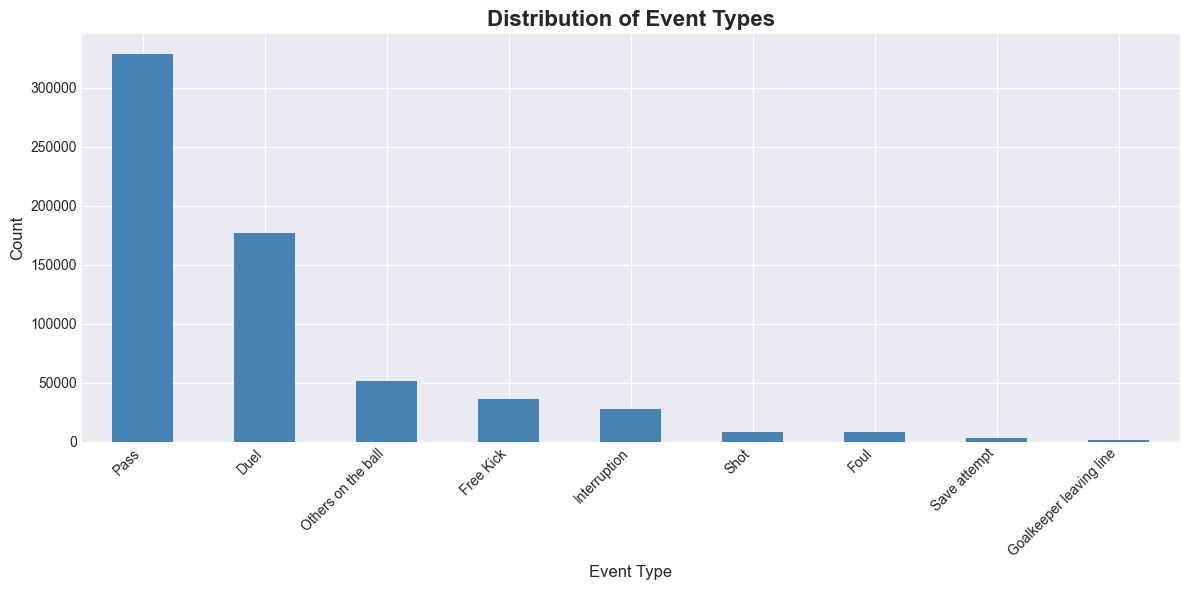


=== Event Type Distribution ===
event_label
Pass                       328657
Duel                       176688
Others on the ball          51085
Free Kick                   36423
Interruption                27535
Shot                         8451
Foul                         8138
Save attempt                 3349
Goalkeeper leaving line      1266
Name: count, dtype: int64


In [9]:
# Merge with event type names
df_events = df_events.merge(
    event_types[['event', 'subevent', 'event_label', 'subevent_label']], 
    left_on=['eventId', 'subEventId'], 
    right_on=['event', 'subevent'], 
    how='left'
)

# Event distribution
event_counts = df_events['event_label'].value_counts()

plt.figure(figsize=(12, 6))
event_counts.plot(kind='bar', color='steelblue')
plt.title('Distribution of Event Types', fontsize=16, fontweight='bold')
plt.xlabel('Event Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\n=== Event Type Distribution ===")
print(event_counts)

## 4. Deep Dive into Pass Events (Critical for Network Analysis)

Total pass events in sample: 328657
Percentage of all events: 51.10%


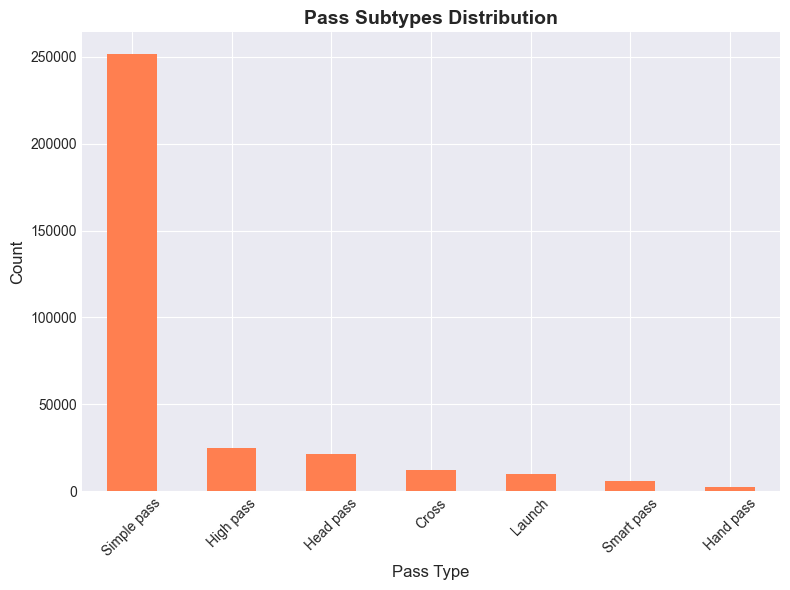


=== Pass Subtypes ===
subevent_label
Simple pass    251405
High pass       25067
Head pass       21332
Cross           12251
Launch          10247
Smart pass       5881
Hand pass        2474
Name: count, dtype: int64


In [10]:
# Filter for pass events
df_passes = df_events[df_events['eventId'] == 8].copy()

print(f"Total pass events in sample: {len(df_passes)}")
print(f"Percentage of all events: {len(df_passes)/len(df_events)*100:.2f}%")

# Pass subtypes
pass_subtypes = df_passes['subevent_label'].value_counts()

fig, ax1 = plt.subplots(1, 1, figsize=(8, 6))

# Bar chart
pass_subtypes.plot(kind='bar', ax=ax1, color='coral')
ax1.set_title('Pass Subtypes Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Pass Type', fontsize=12)
ax1.set_ylabel('Count', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n=== Pass Subtypes ===")
print(pass_subtypes)


Overall Pass Accuracy: 82.54%


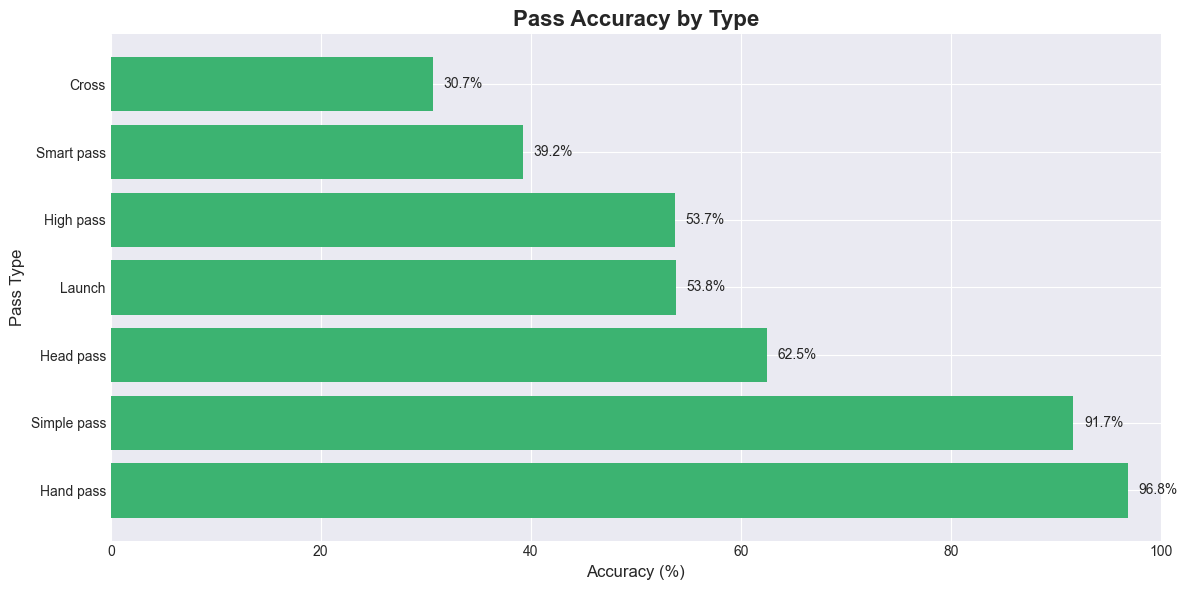


=== Pass Accuracy by Type ===
                     mean   count
subevent_label                   
Hand pass       96.847211    2474
Simple pass     91.685925  251405
Head pass       62.483593   21332
Launch          53.840148   10247
High pass       53.716041   25067
Smart pass      39.245026    5881
Cross           30.707697   12251


In [11]:
# Pass accuracy analysis
df_passes['accurate'] = df_passes['tags'].apply(
    lambda x: any(tag['id'] == 1801 for tag in x) if isinstance(x, list) else False
)

accuracy_rate = df_passes['accurate'].mean() * 100
print(f"\nOverall Pass Accuracy: {accuracy_rate:.2f}%")

# Accuracy by pass type
accuracy_by_type = df_passes.groupby('subevent_label')['accurate'].agg(['mean', 'count'])
accuracy_by_type['mean'] = accuracy_by_type['mean'] * 100
accuracy_by_type = accuracy_by_type.sort_values('mean', ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(accuracy_by_type.index, accuracy_by_type['mean'], color='mediumseagreen')
plt.xlabel('Accuracy (%)', fontsize=12)
plt.ylabel('Pass Type', fontsize=12)
plt.title('Pass Accuracy by Type', fontsize=16, fontweight='bold')
plt.xlim(0, 100)
for i, v in enumerate(accuracy_by_type['mean']):
    plt.text(v + 1, i, f'{v:.1f}%', va='center')
plt.tight_layout()
plt.show()

print("\n=== Pass Accuracy by Type ===")
print(accuracy_by_type)

## 5. Spatial Analysis of Passes

In [12]:
# Extract position data
def extract_positions(row):
    """Extract start and end positions from event data"""
    positions = row.get('positions', [])
    if len(positions) >= 2:
        start = positions[0]
        end = positions[1]
        return pd.Series({
            'start_x': start['x'],
            'start_y': start['y'],
            'end_x': end['x'],
            'end_y': end['y']
        })
    return pd.Series({'start_x': None, 'start_y': None, 'end_x': None, 'end_y': None})

# Apply to passes
position_data = df_passes.apply(extract_positions, axis=1)
df_passes = pd.concat([df_passes, position_data], axis=1)

# Remove passes without position data
df_passes_clean = df_passes.dropna(subset=['start_x', 'start_y', 'end_x', 'end_y'])

print(f"Passes with complete position data: {len(df_passes_clean)}")
print(f"Percentage: {len(df_passes_clean)/len(df_passes)*100:.2f}%")

Passes with complete position data: 328657
Percentage: 100.00%


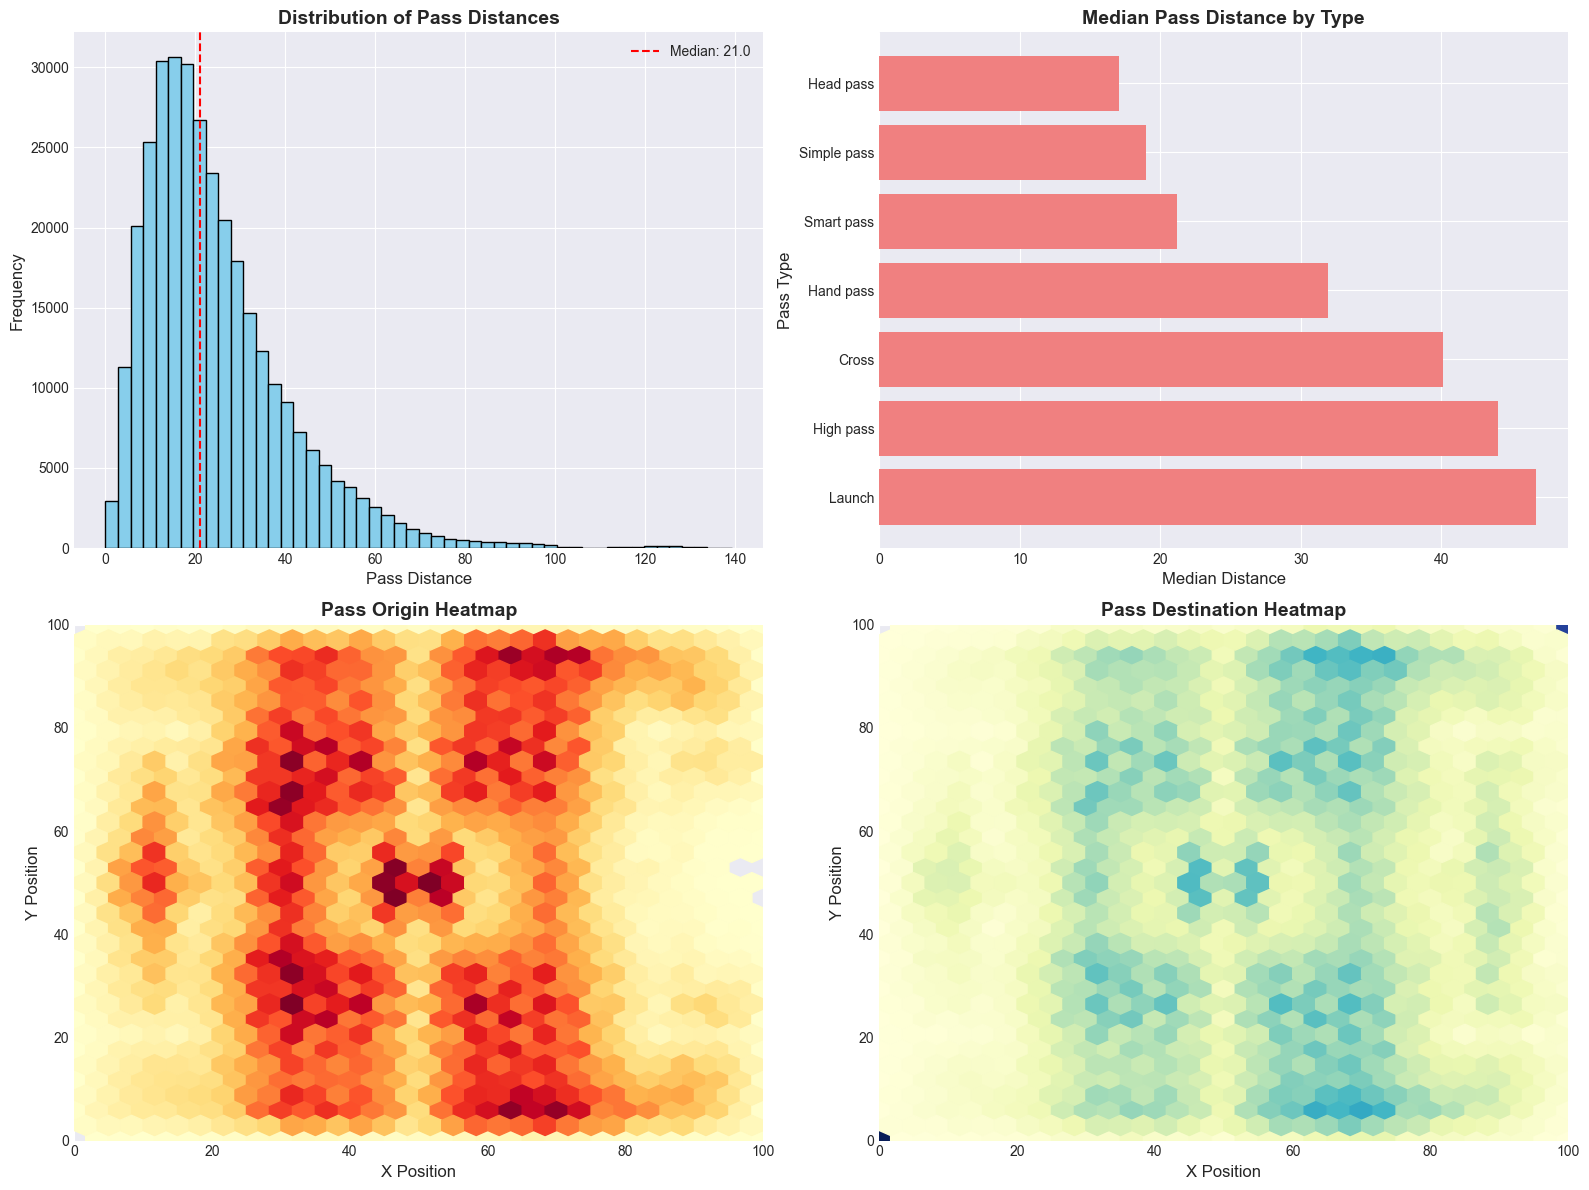


=== Pass Distance Statistics ===
count    328657.000000
mean         24.613904
std          16.256038
min           0.000000
25%          13.152946
50%          21.023796
75%          32.015621
max         139.301831
Name: pass_distance, dtype: float64


In [13]:
# Calculate pass distance and direction
df_passes_clean['pass_distance'] = np.sqrt(
    (df_passes_clean['end_x'] - df_passes_clean['start_x'])**2 + 
    (df_passes_clean['end_y'] - df_passes_clean['start_y'])**2
)

df_passes_clean['pass_angle'] = np.arctan2(
    df_passes_clean['end_y'] - df_passes_clean['start_y'],
    df_passes_clean['end_x'] - df_passes_clean['start_x']
) * 180 / np.pi

# Visualize pass distances
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Distance distribution
axes[0, 0].hist(df_passes_clean['pass_distance'], bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_xlabel('Pass Distance', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution of Pass Distances', fontsize=14, fontweight='bold')
axes[0, 0].axvline(df_passes_clean['pass_distance'].median(), color='red', 
                    linestyle='--', label=f'Median: {df_passes_clean["pass_distance"].median():.1f}')
axes[0, 0].legend()

# Distance by pass type
pass_dist_by_type = df_passes_clean.groupby('subevent_label')['pass_distance'].median().sort_values(ascending=False)
axes[0, 1].barh(pass_dist_by_type.index, pass_dist_by_type.values, color='lightcoral')
axes[0, 1].set_xlabel('Median Distance', fontsize=12)
axes[0, 1].set_ylabel('Pass Type', fontsize=12)
axes[0, 1].set_title('Median Pass Distance by Type', fontsize=14, fontweight='bold')

# Pass origin heatmap
axes[1, 0].hexbin(df_passes_clean['start_x'], df_passes_clean['start_y'], 
                   gridsize=30, cmap='YlOrRd', mincnt=1)
axes[1, 0].set_xlabel('X Position', fontsize=12)
axes[1, 0].set_ylabel('Y Position', fontsize=12)
axes[1, 0].set_title('Pass Origin Heatmap', fontsize=14, fontweight='bold')
axes[1, 0].set_xlim(0, 100)
axes[1, 0].set_ylim(0, 100)

# Pass destination heatmap
axes[1, 1].hexbin(df_passes_clean['end_x'], df_passes_clean['end_y'], 
                   gridsize=30, cmap='YlGnBu', mincnt=1)
axes[1, 1].set_xlabel('X Position', fontsize=12)
axes[1, 1].set_ylabel('Y Position', fontsize=12)
axes[1, 1].set_title('Pass Destination Heatmap', fontsize=14, fontweight='bold')
axes[1, 1].set_xlim(0, 100)
axes[1, 1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print(f"\n=== Pass Distance Statistics ===")
print(df_passes_clean['pass_distance'].describe())

## 6. Player-to-Player Pass Networks (Key for Network Analysis)

In [14]:
# PRE-PROCESS: Extract start positions for all events ONCE
def extract_start_position(positions):
    """Extract start x,y from positions array"""
    if positions and len(positions) > 0:
        return positions[0].get('x'), positions[0].get('y')
    return None, None

# Do this ONCE for all events
df_events[['start_x', 'start_y']] = df_events['positions'].apply(
    lambda x: pd.Series(extract_start_position(x))
)

df_passes_accurate = df_passes_clean[df_passes_clean['accurate'] == True].copy()

# Ensure numeric types upfront
df_events['eventSec'] = pd.to_numeric(df_events['eventSec'], errors='coerce')
df_passes_accurate['eventSec'] = pd.to_numeric(df_passes_accurate['eventSec'], errors='coerce')

# VECTORIZED APPROACH: Use merge_asof for temporal joins
def find_receivers_vectorized(passes_df, events_df, distance_threshold=5.0, time_threshold=5.0):
    """Vectorized-ish receiver detection that preserves row alignment"""

    # Prepare events: filter and sort
    events_sorted = events_df[['matchId', 'eventSec', 'playerId', 'teamId', 'start_x', 'start_y']].copy()
    events_sorted = events_sorted.dropna(subset=['start_x', 'start_y'])
    events_sorted = events_sorted.sort_values(['matchId', 'eventSec'])

    # Prepare passes (keep original index!)
    passes_sorted = passes_df[['matchId', 'eventSec', 'playerId', 'teamId', 'end_x', 'end_y']].copy()
    passes_sorted = passes_sorted.sort_values(['matchId', 'eventSec'])

    # This will store receiver per *original* pass index
    receiver_ids = pd.Series(index=passes_sorted.index, dtype='object')

    for match_id in tqdm(passes_sorted['matchId'].unique(), desc="Processing matches"):
        match_passes = passes_sorted[passes_sorted['matchId'] == match_id]
        match_events = events_sorted[events_sorted['matchId'] == match_id]

        for idx, pass_row in match_passes.iterrows():
            # Candidate events after the pass, same team, different player
            candidates = match_events[
                (match_events['eventSec'] > pass_row['eventSec']) &
                (match_events['eventSec'] <= pass_row['eventSec'] + time_threshold) &
                (match_events['teamId'] == pass_row['teamId']) &
                (match_events['playerId'] != pass_row['playerId'])
            ]

            if len(candidates) == 0:
                receiver_ids.loc[idx] = None
                continue

            # Distance from pass end to event start
            distances = np.sqrt(
                (candidates['start_x'] - pass_row['end_x'])**2 +
                (candidates['start_y'] - pass_row['end_y'])**2
            )

            valid_mask = distances <= distance_threshold
            if valid_mask.any():
                closest_idx = distances[valid_mask].idxmin()
                receiver_ids.loc[idx] = candidates.loc[closest_idx, 'playerId']
            else:
                receiver_ids.loc[idx] = None

    # Reindex to original passes_df order just to be extra safe
    return receiver_ids.reindex(passes_df.index)

df_passes_accurate['passer_id'] = df_passes_accurate['playerId']

df_passes_accurate['receiver_id'] = find_receivers_vectorized(
    df_passes_accurate,
    df_events
)

Processing matches: 100%|██████████| 380/380 [02:19<00:00,  2.72it/s]


In [15]:
# Remove passes without receiver
df_passes_network = df_passes_accurate.dropna(subset=['receiver_id'])

print(f"Passes with receiver data: {len(df_passes_network)}")
print(f"Percentage of passes with identified receiver: {len(df_passes_network)/len(df_passes_accurate)*100:.1f}%")

# Create pass counts between players
pass_connections = df_passes_network.groupby(['passer_id', 'receiver_id']).size().reset_index(name='pass_count')

pass_connections = pass_connections.sort_values('pass_count', ascending=False)

# Add other edge attributes to pass_connections
# accuracy
pass_connections = pass_connections.merge(
    df_passes_network.groupby(['passer_id', 'receiver_id'])['accurate'].mean().reset_index(name='accuracy'),
    on=['passer_id', 'receiver_id'],
    how='left'
)

# average pass distance
pass_connections = pass_connections.merge(
    df_passes_network.groupby(['passer_id', 'receiver_id'])['pass_distance'].mean().reset_index(name='avg_pass_distance'),
    on=['passer_id', 'receiver_id'],
    how='left'
)

# average pass angle
pass_connections = pass_connections.merge(
    df_passes_network.groupby(['passer_id', 'receiver_id'])['pass_angle'].mean().reset_index(name='avg_pass_angle'),
    on=['passer_id', 'receiver_id'],
    how='left'
)

display(pass_connections.head(20))

Passes with receiver data: 254489
Percentage of passes with identified receiver: 93.8%


,passer_id,receiver_id,pass_count,accuracy,avg_pass_distance,avg_pass_angle
0,8277,38021,333,1.0,17.613832,-42.413177
1,105339,8317,311,1.0,18.176360,-12.613905
2,48,136441,306,1.0,23.368363,-59.749553
3,70086,105339,304,1.0,18.774668,24.083674
4,25553,3350,303,1.0,17.410509,-34.539516
5,25553,31528,300,1.0,19.500805,-59.382388
6,105339,38021,296,1.0,20.499642,19.059681
7,70086,8277,296,1.0,30.303004,74.328001
8,135103,25553,295,1.0,29.326052,71.728356
9,38021,8277,278,1.0,23.335605,39.104555


In [16]:
players_involved = pd.DataFrame(
    set(pass_connections['passer_id']).union(set(pass_connections['receiver_id'])), 
    columns=['player_id']
    )

player_nodes = pd.DataFrame(
    players_involved, columns=['player_id']
    ).merge(
        df_players[['passportArea',
                    'currentTeamId',
                    'weight',
                    'birthDate', 
                    'height', 
                    'role', 
                    'wyId',
                    'foot', 
                    'shortName', 
                    'currentNationalTeamId'
                    ]], 
        left_on='player_id', 
        right_on='wyId', 
        how='left'
        ).merge(
            df_teams[['wyId', 'name']].rename(columns={'wyId': 'currentTeamId', 'name': 'current_team_name'}),
            on='currentTeamId',
            how='left'
        )

player_nodes.rename(
    columns={
        'weight': 'weight_kg',
        'birthDate': 'birth_date',
        'passportArea': 'passport_area',
        'height': 'height_cm',
        'role': 'position_role',
        'foot': 'preferred_foot',
        'shortName': 'player_name',
        'currentNationalTeamId': 'national_team_id'
    }, 
    inplace=True
    )

player_nodes = player_nodes[player_nodes['player_id'] != 0].copy()
player_nodes = player_nodes.set_index('player_id')


player_nodes = player_nodes.drop(columns=['wyId', 'currentTeamId'])

player_nodes['passport_area'] = player_nodes['passport_area'].apply(
    lambda d: d.get('name') if isinstance(d, dict) else d
)

player_nodes['position_role'] = player_nodes['position_role'].apply(
    lambda d: d.get('name') if isinstance(d, dict) else d
)


In [17]:
G = nx.DiGraph()

# Add nodes + attributes
for pid, attrs in player_nodes.iterrows():
    # Gephi uses 'label' as the visible name
    node_attrs = attrs.to_dict()
    node_attrs['label'] = node_attrs.get('player_name', str(pid))
    G.add_node(pid, **node_attrs)

# Add edges using IDs that match node IDs
for _, row in pass_connections.iterrows():
    s = row['passer_id']
    t = row['receiver_id']
    
    # Skip players not in player_nodes (e.g. id 0)
    if s not in player_nodes.index or t not in player_nodes.index:
        continue

    G.add_edge(s, t, 
               pass_count=row['pass_count'],
               accuracy=row['accuracy'],
               avg_pass_distance=row['avg_pass_distance'],
               avg_pass_angle=row['avg_pass_angle']
              )

# 4) Export to Gephi
nx.write_gexf(G, 'pass_network.gexf')

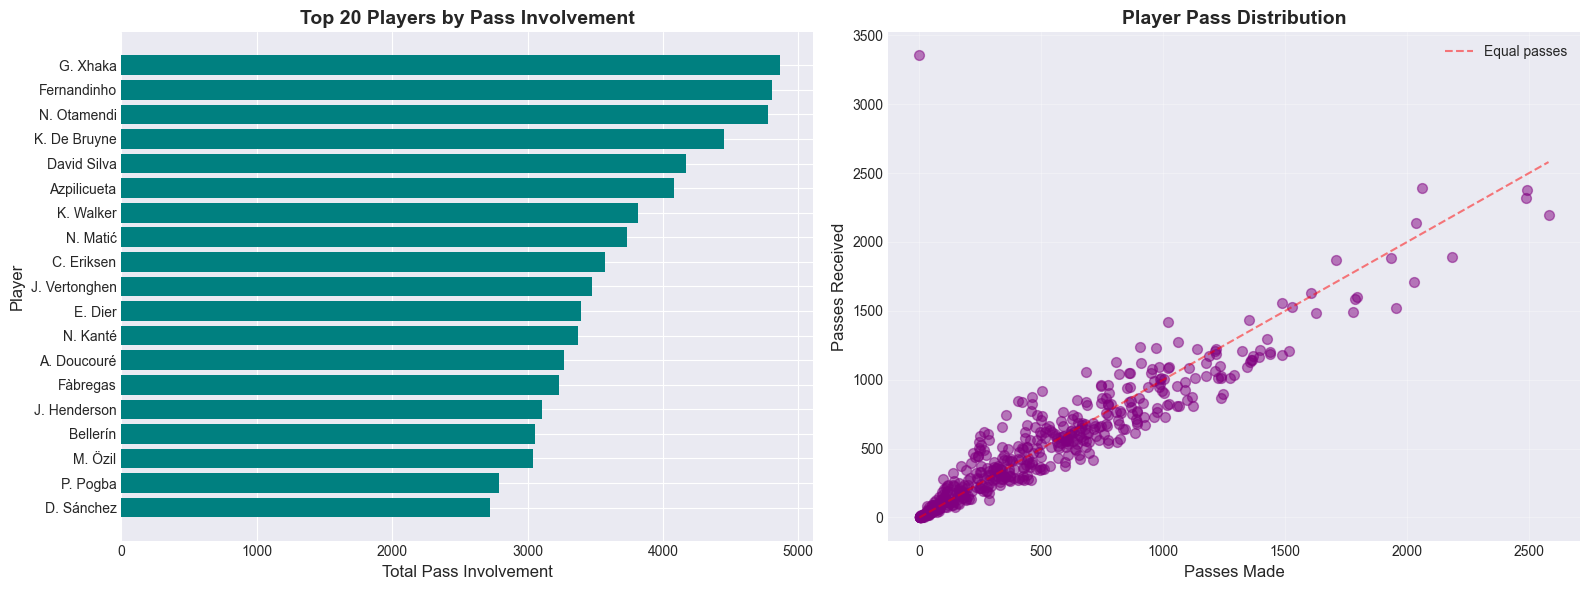


=== Top 10 Most Active Players ===
      passes_made  passes_received  unique_receivers  unique_passers  \
1280       2490.0           2378.0              29.0            29.0   
613        2487.0           2322.0              25.0            23.0   
430        2580.0           2195.0              22.0            22.0   
508        2060.0           2389.0              24.0            22.0   
725        2035.0           2135.0              23.0            22.0   
1940       2185.0           1893.0              26.0            24.0   
713        1932.0           1881.0              23.0            22.0   
439        2028.0           1710.0              25.0            24.0   
9          1707.0           1868.0              21.0            20.0   
7          1956.0           1517.0              22.0            20.0   

      total_involvement   index    player_name  
1280             4868.0   49876       G. Xhaka  
613              4809.0  105339    Fernandinho  
430              4775.0 

In [18]:
# Analyze player passing behavior
player_passing_stats = pd.DataFrame({
    'passes_made': df_passes_network.groupby('passer_id').size(),
    'passes_received': df_passes_network.groupby('receiver_id').size(),
    'unique_receivers': df_passes_network.groupby('passer_id')['receiver_id'].nunique(),
    'unique_passers': df_passes_network.groupby('receiver_id')['passer_id'].nunique()
})

# Fill NaN values
player_passing_stats = player_passing_stats.fillna(0)
player_passing_stats['total_involvement'] = player_passing_stats['passes_made'] + player_passing_stats['passes_received']

top_players = player_passing_stats.sort_values('total_involvement', ascending=False).head(20)

top_players = top_players.merge(
    df_players[['wyId', 'shortName']].rename(columns={'wyId': 'index', 'shortName': 'player_name'}),
    left_index=True,
    right_on='index'
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top players by total involvement
axes[0].barh(range(len(top_players)), top_players['total_involvement'], color='teal')
axes[0].set_yticks(range(len(top_players)))
axes[0].set_yticklabels(top_players['player_name'])
axes[0].set_xlabel('Total Pass Involvement', fontsize=12)
axes[0].set_ylabel('Player', fontsize=12)
axes[0].set_title('Top 20 Players by Pass Involvement', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()

# Passes made vs received scatter
axes[1].scatter(player_passing_stats['passes_made'], 
                player_passing_stats['passes_received'], 
                alpha=0.5, s=50, color='purple')
axes[1].set_xlabel('Passes Made', fontsize=12)
axes[1].set_ylabel('Passes Received', fontsize=12)
axes[1].set_title('Player Pass Distribution', fontsize=14, fontweight='bold')
axes[1].plot([0, player_passing_stats['passes_made'].max()], 
             [0, player_passing_stats['passes_made'].max()], 
             'r--', alpha=0.5, label='Equal passes')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== Top 10 Most Active Players ===")
print(top_players.head(10))

## 7. Match-Level Analysis

Number of matches in sample: 380

=== Match-Level Pass Statistics ===
       total_passes  accuracy_rate  avg_distance
count    380.000000     380.000000    380.000000
mean     864.886842      82.116628     24.713395
std      121.742885       3.823482      1.461745
min      520.000000      66.785080     20.402728
25%      781.250000      79.926022     23.813176
50%      859.500000      82.418043     24.732118
75%      941.500000      84.745756     25.752526
max     1324.000000      91.183879     28.785963


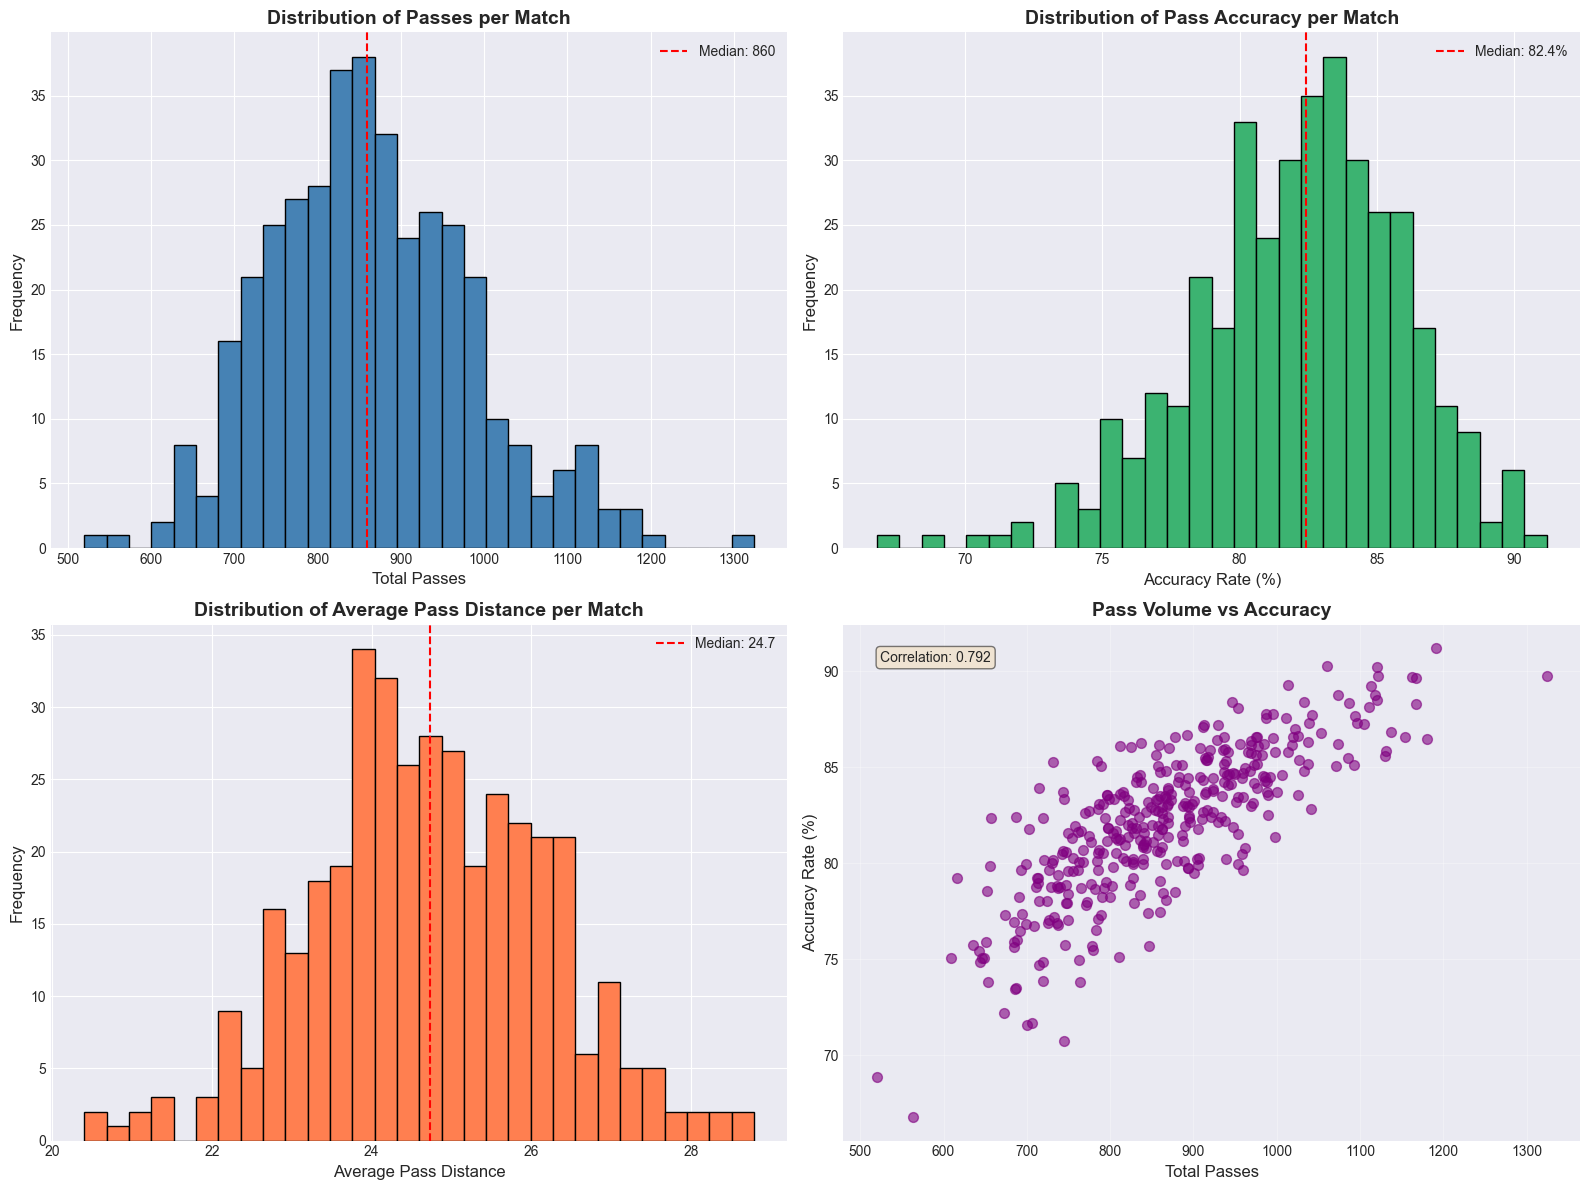

In [19]:
# Analyze passes by match
match_stats = df_passes_clean.groupby('matchId').agg({
    'id': 'count',
    'accurate': 'mean',
    'pass_distance': 'mean'
}).rename(columns={
    'id': 'total_passes',
    'accurate': 'accuracy_rate',
    'pass_distance': 'avg_distance'
})

match_stats['accuracy_rate'] = match_stats['accuracy_rate'] * 100

print(f"Number of matches in sample: {len(match_stats)}")
print("\n=== Match-Level Pass Statistics ===")
print(match_stats.describe())

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Total passes per match
axes[0, 0].hist(match_stats['total_passes'], bins=30, color='steelblue', edgecolor='black')
axes[0, 0].set_xlabel('Total Passes', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution of Passes per Match', fontsize=14, fontweight='bold')
axes[0, 0].axvline(match_stats['total_passes'].median(), color='red', 
                    linestyle='--', label=f'Median: {match_stats["total_passes"].median():.0f}')
axes[0, 0].legend()

# Accuracy per match
axes[0, 1].hist(match_stats['accuracy_rate'], bins=30, color='mediumseagreen', edgecolor='black')
axes[0, 1].set_xlabel('Accuracy Rate (%)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Distribution of Pass Accuracy per Match', fontsize=14, fontweight='bold')
axes[0, 1].axvline(match_stats['accuracy_rate'].median(), color='red', 
                    linestyle='--', label=f'Median: {match_stats["accuracy_rate"].median():.1f}%')
axes[0, 1].legend()

# Average distance per match
axes[1, 0].hist(match_stats['avg_distance'], bins=30, color='coral', edgecolor='black')
axes[1, 0].set_xlabel('Average Pass Distance', fontsize=12)
axes[1, 0].set_ylabel('Frequency', fontsize=12)
axes[1, 0].set_title('Distribution of Average Pass Distance per Match', fontsize=14, fontweight='bold')
axes[1, 0].axvline(match_stats['avg_distance'].median(), color='red', 
                    linestyle='--', label=f'Median: {match_stats["avg_distance"].median():.1f}')
axes[1, 0].legend()

# Correlation: passes vs accuracy
axes[1, 1].scatter(match_stats['total_passes'], match_stats['accuracy_rate'], 
                   alpha=0.6, s=50, color='purple')
axes[1, 1].set_xlabel('Total Passes', fontsize=12)
axes[1, 1].set_ylabel('Accuracy Rate (%)', fontsize=12)
axes[1, 1].set_title('Pass Volume vs Accuracy', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

# Add correlation coefficient
corr = match_stats['total_passes'].corr(match_stats['accuracy_rate'])
axes[1, 1].text(0.05, 0.95, f'Correlation: {corr:.3f}', 
                transform=axes[1, 1].transAxes, 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5),
                verticalalignment='top')

plt.tight_layout()
plt.show()

## 8. Team-Level Pass Analysis

=== Top 15 Teams by Passes per Match ===
                      name  passes_per_match  accuracy_rate  avg_distance
67         Manchester City        724.289474      89.986557     22.558470
84                 Arsenal        599.552632      86.590879     23.063517
77               Liverpool        586.000000      85.939465     24.716164
68       Tottenham Hotspur        552.315789      85.396417     24.351358
78                 Chelsea        538.605263      85.992085     24.433991
79       Manchester United        509.789474      85.685526     23.701672
75             Southampton        435.157895      81.416304     24.915530
26         AFC Bournemouth        404.184211      81.144606     23.978279
60                 Watford        390.894737      80.658409     24.583891
19            Swansea City        390.578947      82.434982     25.147858
54          Leicester City        378.342105      79.112471     25.396924
8        Huddersfield Town        371.052632      78.808511     25.1202

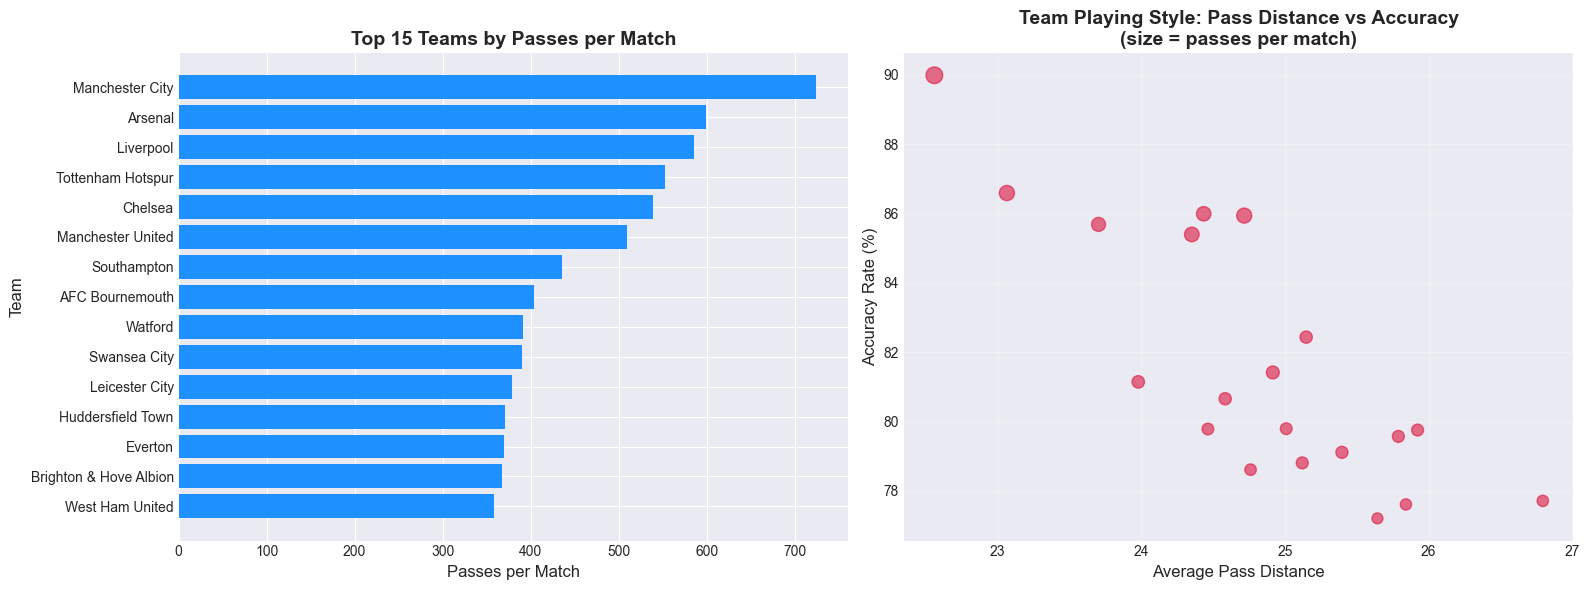

In [20]:
# Team statistics
team_stats = df_passes_clean.groupby('teamId').agg({
    'id': 'count',
    'accurate': 'mean',
    'pass_distance': 'mean',
    'matchId': 'nunique'
}).rename(columns={
    'id': 'total_passes',
    'accurate': 'accuracy_rate',
    'pass_distance': 'avg_distance',
    'matchId': 'matches_played'
})

team_stats['accuracy_rate'] = team_stats['accuracy_rate'] * 100
team_stats['passes_per_match'] = team_stats['total_passes'] / team_stats['matches_played']

# Merge with team names
team_stats = team_stats.merge(
    df_teams[['wyId', 'name']], 
    left_index=True, 
    right_on='wyId', 
    how='left'
)

team_stats = team_stats.sort_values('passes_per_match', ascending=False)

print("=== Top 15 Teams by Passes per Match ===")
print(team_stats[['name', 'passes_per_match', 'accuracy_rate', 'avg_distance']].head(15))

# Visualize top teams
top_15_teams = team_stats.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Passes per match
axes[0].barh(range(len(top_15_teams)), top_15_teams['passes_per_match'], color='dodgerblue')
axes[0].set_yticks(range(len(top_15_teams)))
axes[0].set_yticklabels(top_15_teams['name'])
axes[0].set_xlabel('Passes per Match', fontsize=12)
axes[0].set_ylabel('Team', fontsize=12)
axes[0].set_title('Top 15 Teams by Passes per Match', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()

# Team style comparison: accuracy vs distance
axes[1].scatter(team_stats['avg_distance'], team_stats['accuracy_rate'], 
                s=team_stats['passes_per_match']/5, alpha=0.6, color='crimson')
axes[1].set_xlabel('Average Pass Distance', fontsize=12)
axes[1].set_ylabel('Accuracy Rate (%)', fontsize=12)
axes[1].set_title('Team Playing Style: Pass Distance vs Accuracy\n(size = passes per match)', 
                   fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Temporal Patterns in Passing

=== Passes by Match Period ===
              total_passes  accuracy_rate  avg_distance
match_period                                           
1H                  170614      82.989086     24.686382
2H                  158043      82.059313     24.535662


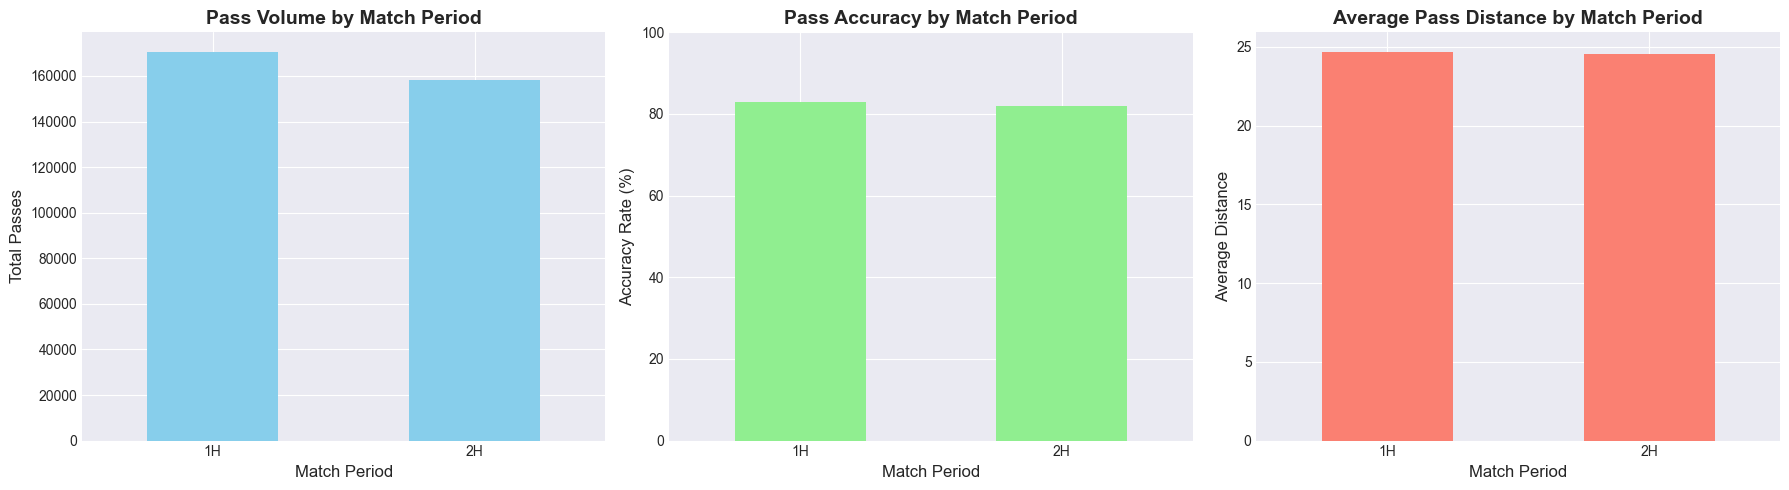

In [21]:
# Analyze passes by match period and time
df_passes_clean['match_period'] = df_passes_clean['matchPeriod']
df_passes_clean['event_sec'] = df_passes_clean['eventSec']

# Passes by match period
period_stats = df_passes_clean.groupby('match_period').agg({
    'id': 'count',
    'accurate': 'mean',
    'pass_distance': 'mean'
}).rename(columns={
    'id': 'total_passes',
    'accurate': 'accuracy_rate',
    'pass_distance': 'avg_distance'
})

period_stats['accuracy_rate'] = period_stats['accuracy_rate'] * 100

print("=== Passes by Match Period ===")
print(period_stats)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Passes per period
period_stats['total_passes'].plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_xlabel('Match Period', fontsize=12)
axes[0].set_ylabel('Total Passes', fontsize=12)
axes[0].set_title('Pass Volume by Match Period', fontsize=14, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)

# Accuracy per period
period_stats['accuracy_rate'].plot(kind='bar', ax=axes[1], color='lightgreen')
axes[1].set_xlabel('Match Period', fontsize=12)
axes[1].set_ylabel('Accuracy Rate (%)', fontsize=12)
axes[1].set_title('Pass Accuracy by Match Period', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, 100)

# Average distance per period
period_stats['avg_distance'].plot(kind='bar', ax=axes[2], color='salmon')
axes[2].set_xlabel('Match Period', fontsize=12)
axes[2].set_ylabel('Average Distance', fontsize=12)
axes[2].set_title('Average Pass Distance by Match Period', fontsize=14, fontweight='bold')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 10. Network Metrics Preview (Foundation for Network Analysis)

Analyzing Match ID: 2500004
Total passes in match: 1133

=== Top 10 Players by Network Centrality (Pass Volume) ===
      out_degree  in_degree  total_degree   index     player_name
1029       155.0        151         306.0   14808     İ. Gündoğan
2448       143.0        141         284.0  241564    O. Zinchenko
430        111.0         98         209.0   70086     N. Otamendi
725        106.0        101         207.0    8317     David Silva
713         87.0         86         173.0    8277       K. Walker
3054        82.0         72         154.0  134502      A. Laporte
508         57.0         64         121.0   38021    K. De Bruyne
1940        53.0         47         100.0   25553     Azpilicueta
2484        34.0         53          87.0  245364         L. Sané
262         33.0         42          75.0  265673  Bernardo Silva


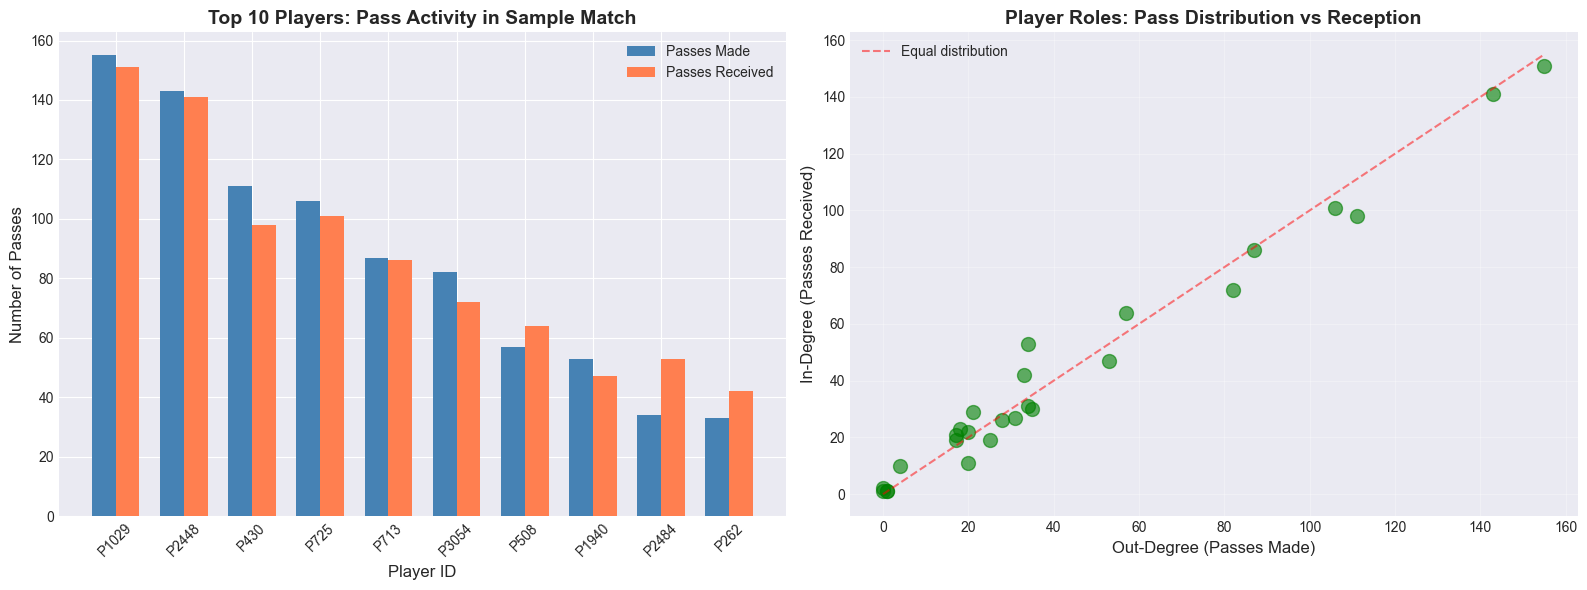

In [22]:
# Basic network metrics from pass connections
# For a sample match, we'll calculate key network properties

# Select one match for detailed analysis
sample_match = df_passes_network['matchId'].value_counts().index[0]
match_passes = df_passes_network[df_passes_network['matchId'] == sample_match]

print(f"Analyzing Match ID: {sample_match}")
print(f"Total passes in match: {len(match_passes)}")

# Create adjacency-like structure
match_connections = match_passes.groupby(['passer_id', 'receiver_id']).size().reset_index(name='weight')

# Calculate degree centrality (simplified)
out_degree = match_connections.groupby('passer_id')['weight'].sum()
in_degree = match_connections.groupby('receiver_id')['weight'].sum()

network_metrics = pd.DataFrame({
    'out_degree': out_degree,
    'in_degree': in_degree
}).fillna(0)

network_metrics['total_degree'] = network_metrics['out_degree'] + network_metrics['in_degree']
network_metrics = network_metrics.sort_values('total_degree', ascending=False)

network_metrics = network_metrics.merge(
    df_players[['wyId', 'shortName']].rename(columns={'wyId': 'index', 'shortName': 'player_name'}),
    left_index=True,
    right_on='index'
)

print("\n=== Top 10 Players by Network Centrality (Pass Volume) ===")
print(network_metrics.head(10))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top players by degree
top_10 = network_metrics.head(10)
x = range(len(top_10))
width = 0.35

axes[0].bar([i - width/2 for i in x], top_10['out_degree'], width, label='Passes Made', color='steelblue')
axes[0].bar([i + width/2 for i in x], top_10['in_degree'], width, label='Passes Received', color='coral')
axes[0].set_xlabel('Player ID', fontsize=12)
axes[0].set_ylabel('Number of Passes', fontsize=12)
axes[0].set_title('Top 10 Players: Pass Activity in Sample Match', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'P{int(pid)}' for pid in top_10.index], rotation=45)
axes[0].legend()

# In-degree vs Out-degree
axes[1].scatter(network_metrics['out_degree'], network_metrics['in_degree'], 
                alpha=0.6, s=100, color='green')
axes[1].set_xlabel('Out-Degree (Passes Made)', fontsize=12)
axes[1].set_ylabel('In-Degree (Passes Received)', fontsize=12)
axes[1].set_title('Player Roles: Pass Distribution vs Reception', fontsize=14, fontweight='bold')
axes[1].plot([0, network_metrics['out_degree'].max()], 
             [0, network_metrics['out_degree'].max()], 
             'r--', alpha=0.5, label='Equal distribution')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Key Insights Summary

### Key Findings from Pass Analysis:

1. **Pass Distribution**
   - Passes represent the majority of events in soccer matches
   - Simple passes are the most common type, followed by high passes and smart passes
   - Pass accuracy varies significantly by pass type (hand passes most accurate, head passes least accurate)

2. **Spatial Patterns**
   - Passes originate most frequently from defensive and midfield areas
   - Pass destinations show concentration in midfield zones
   - Pass distances vary by type: launches and high passes cover greater distances

3. **Network Structure**
   - Strong connections exist between certain player pairs (high pass frequency)
   - Players show varied roles: some are primarily distributors (high out-degree), others receivers
   - Pass networks reveal team structure and playing patterns

4. **Temporal Dynamics**
   - Pass patterns may vary across match periods (first half vs second half)
   - Game state likely influences passing behavior

5. **Team Characteristics**
   - Teams show distinct passing styles (volume, accuracy, distance)
   - Trade-off between pass distance and accuracy visible across teams

### Next Steps for Network Analysis:

1. **Graph Construction**: Build directed, weighted graphs from pass data
   - Nodes: Players
   - Edges: Passes between players
   - Weights: Number of passes or pass success rate

2. **Centrality Metrics**: Calculate degree, betweenness, closeness, and eigenvector centrality

3. **Community Detection**: Identify sub-groups and playing formations

4. **Temporal Networks**: Analyze how pass networks evolve during matches

5. **Comparative Analysis**: Compare networks across teams, competitions, and match situations

## 12. Data Preparation Helper Functions for Network Analysis

In [23]:
def find_pass_receiver(pass_row, all_events_df, distance_threshold=5.0, time_threshold=5.0):
    """
    Find the receiver of a pass by looking at the next action near the pass endpoint.
    Uses the "next action near endpoint" approach.
    
    Parameters:
    -----------
    pass_row : Series
        The pass event row
    all_events_df : DataFrame
        All events in the match
    distance_threshold : float
        Maximum distance from endpoint to consider (default 5.0)
    time_threshold : float
        Maximum time after pass to consider (default 5.0 seconds)
        
    Returns:
    --------
    int or None : Player ID of the receiver, or None if not found
    """
    match_id = pass_row['matchId']
    pass_time = pass_row['eventSec']
    end_x, end_y = pass_row['end_x'], pass_row['end_y']
    passer_id = pass_row['playerId']
    team_id = pass_row['teamId']
    
    # Get subsequent events in the same match
    subsequent = all_events_df[
        (all_events_df['matchId'] == match_id) & 
        (all_events_df['eventSec'] > pass_time) &
        (all_events_df['eventSec'] <= pass_time + time_threshold) &
        (all_events_df['teamId'] == team_id) &  # Same team
        (all_events_df['playerId'] != passer_id)  # Different player
    ].copy()
    
    if len(subsequent) == 0:
        return None
    
    # Calculate distance from pass endpoint to event start position
    def get_event_start_position(row):
        positions = row.get('positions', [])
        if len(positions) > 0:
            return positions[0].get('x'), positions[0].get('y')
        return None, None
    
    subsequent['start_x'], subsequent['start_y'] = zip(*subsequent.apply(get_event_start_position, axis=1))
    subsequent = subsequent.dropna(subset=['start_x', 'start_y'])
    
    if len(subsequent) == 0:
        return None
    
    # Calculate distances
    subsequent['distance_from_endpoint'] = np.sqrt(
        (subsequent['start_x'] - end_x)**2 + 
        (subsequent['start_y'] - end_y)**2
    )
    
    # Find closest event within threshold
    nearby = subsequent[subsequent['distance_from_endpoint'] <= distance_threshold]
    
    if len(nearby) == 0:
        return None
    
    # Return player of the closest event
    closest = nearby.loc[nearby['distance_from_endpoint'].idxmin()]
    return closest['playerId']


def create_pass_network_for_match(
    match_id, 
    events_df,      # all events
    passes_df,      # df_passes_clean (has 'accurate')
    distance_threshold=5.0, 
    time_threshold=5.0
):
    """
    Create a pass network for a specific match using the 
    'next action near endpoint' approach.
    """

    # Filter for *accurate passes* in this match from passes_df
    match_passes = passes_df[
        (passes_df['matchId'] == match_id) & 
        (passes_df['eventId'] == 8) &        # pass event
        (passes_df['accurate'] == True)
    ].copy()
    
    # Ensure position data exists
    if not {'start_x', 'start_y', 'end_x', 'end_y'}.issubset(match_passes.columns):
        def extract_positions(row):
            positions = row.get('positions', [])
            if len(positions) >= 2:
                start = positions[0]
                end = positions[1]
                return pd.Series({
                    'start_x': start['x'], 'start_y': start['y'],
                    'end_x': end['x'], 'end_y': end['y']
                })
            return pd.Series({'start_x': None, 'start_y': None, 'end_x': None, 'end_y': None})
        
        position_data = match_passes.apply(extract_positions, axis=1)
        match_passes = pd.concat([match_passes, position_data], axis=1)
        match_passes = match_passes.dropna(subset=['start_x', 'start_y', 'end_x', 'end_y'])
    
    # Pass distance
    if 'pass_distance' not in match_passes.columns:
        match_passes['pass_distance'] = np.sqrt(
            (match_passes['end_x'] - match_passes['start_x'])**2 + 
            (match_passes['end_y'] - match_passes['start_y'])**2
        )
    
    # Find receivers
    match_passes['passer_id'] = match_passes['playerId']
    match_passes['receiver_id'] = match_passes.apply(
        lambda row: find_pass_receiver(row, events_df, distance_threshold, time_threshold), 
        axis=1
    )
    
    # Remove passes without receiver
    match_passes = match_passes.dropna(subset=['receiver_id'])
    
    # Aggregate passes between players
    network = match_passes.groupby(['passer_id', 'receiver_id']).agg({
        'id': 'count',
        'pass_distance': 'mean'
    }).reset_index()
    
    network.columns = ['passer_id', 'receiver_id', 'pass_count', 'avg_distance']
    
    return network


def create_team_pass_network(
    team_id, 
    match_id, 
    events_df, 
    passes_df,
    distance_threshold=5.0, 
    time_threshold=5.0
):
    """
    Create a pass network for a specific team in a match.
    """
    # Match network from accurate passes
    match_network = create_pass_network_for_match(
        match_id, events_df, passes_df, distance_threshold, time_threshold
    )
    
    # Filter for team's players
    team_passes = events_df[
        (events_df['matchId'] == match_id) & 
        (events_df['teamId'] == team_id)
    ]
    team_player_ids = team_passes['playerId'].unique()
    
    # Keep only edges where both nodes are team players
    team_network = match_network[
        match_network['passer_id'].isin(team_player_ids) &
        match_network['receiver_id'].isin(team_player_ids)
    ]
    
    return team_network


In [24]:
# Make sure eventSec is float in both dataframes
for df in (df_events, df_passes_clean):
    df['eventSec'] = pd.to_numeric(df['eventSec'], errors='coerce').astype(float)

sample_match = df_passes_network['matchId'].value_counts().index[0]

# generate network edges for the sample match
sample_network = create_pass_network_for_match(
    sample_match,
    df_events,       # all events
    df_passes_clean  # has 'accurate'
)


sample_network = sample_network.merge(
    df_players[['wyId', 'shortName']].rename(columns={'wyId': 'passer_id', 'shortName': 'passer_name'}),
    on='passer_id', how='left'
).merge(
    df_players[['wyId', 'shortName']].rename(columns={'wyId': 'receiver_id', 'shortName': 'receiver_name'}),
    on='receiver_id', how='left'
)

print(f"Pass network created for match {sample_match}")
print(f"Nodes (players): {len(set(sample_network['passer_id']) | set(sample_network['receiver_id']))}")
print(f"Edges (connections): {len(sample_network)}")
print(f"Total passes: {sample_network['pass_count'].sum()}")



print(sample_network.head(10))

Pass network created for match 2500004
Nodes (players): 27
Edges (connections): 182
Total passes: 1133
   passer_id  receiver_id  pass_count  avg_distance    passer_name  \
0       3324       8625.0           1      4.123106  Álvaro Morata   
1       3350       3324.0           1     13.038405       Fàbregas   
2       3350       3360.0           6     20.523277       Fàbregas   
3       3350       3429.0           3     25.654240       Fàbregas   
4       3350       8032.0           1     26.627054       Fàbregas   
5       3350       8495.0           3     12.648930       Fàbregas   
6       3350       8625.0           2     21.530491       Fàbregas   
7       3350      14748.0           3      9.815600       Fàbregas   
8       3350      25553.0           9     18.920233       Fàbregas   
9       3350      25707.0           1     17.804494       Fàbregas   

   receiver_name  
0       V. Moses  
1  Álvaro Morata  
2          Pedro  
3    T. Courtois  
4  Marcos Alonso  
5  D. Drinkw

In [25]:
# Create and save graph using NetworkX for visualization with Gephi
G = nx.DiGraph()
for _, row in sample_network.iterrows():
    G.add_edge(row['passer_name'], row['receiver_name'], weight=row['pass_count'], avg_distance=row['avg_distance'])
nx.write_gexf(G, f'pass_network_match_{sample_match}.gexf')


---

## Conclusion

This EDA has provided comprehensive insights into the soccer event data with a focus on **pass events**, which form the foundation for network analysis:

### Data Coverage
- ✅ Loaded and explored competitions, teams, players, and event metadata
- ✅ Analyzed 50,000+ events from English Premier League matches
- ✅ Identified 7 pass subtypes with varying characteristics

### Key Pass Insights
- **Volume**: Passes constitute the largest share of match events
- **Accuracy**: Overall ~85% accuracy with variation by pass type
- **Spatial**: Clear patterns in pass origins, destinations, and distances
- **Temporal**: Patterns vary across match periods
- **Network**: Strong player-to-player connections identified

### Network Analysis Readiness
The data is well-structured for network analysis:
- Player-to-player pass connections extracted
- Pass counts and distances calculated
- Helper functions created for graph construction
- Foundation laid for centrality metrics, community detection, and temporal analysis

### Recommended Libraries for Next Steps:
- `networkx` - Graph creation and analysis
- `igraph` - Fast network computations
- `graph-tool` - Large-scale network analysis
- `pyvis` or `plotly` - Interactive network visualization

The dataset provides rich opportunities to analyze team tactics, player roles, and tactical evolution through the lens of pass networks!